# 01 - Exploratory Data Analysis

**Coursework Part 01, Task 1**

**Goal:** understand the structure of the Telco Customer Churn dataset, check data quality, and find which customer attributes are linked to churn. The findings here guide the preprocessing and modelling choices in the next notebook.

## Setup And Data Loading

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style = "whitegrid", context = "notebook")
pd.set_option("display.max_columns", None)

# Paths (this notebook lives in notebooks/, data in data/)
DATA_PATH = Path("../data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")
FIG_DIR = Path("../figures")
FIG_DIR.mkdir(exist_ok = True)

# One consistent colour for each class across every plot
CHURN_PALETTE = {"No": "#4C72B0", "Yes": "#DD5952"}


def save_fig(name):
    """Save the current figure to figures/ so it can go straight into the report."""
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi = 300, bbox_inches = "tight")

In [2]:
df = pd.read_csv(DATA_PATH)
print(f"Rows: {df.shape[0]:,}  |  Columns: {df.shape[1]}")

Rows: 7,043  |  Columns: 21


## First Look At The Raw Data

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Number of unique values per column — helps separate numerical from categorical features
df.nunique().sort_values()

gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
PhoneService           2
PaperlessBilling       2
Churn                  2
MultipleLines          3
TechSupport            3
StreamingTV            3
OnlineBackup           3
DeviceProtection       3
StreamingMovies        3
Contract               3
OnlineSecurity         3
InternetService        3
PaymentMethod          4
tenure                73
MonthlyCharges      1585
TotalCharges        6531
customerID          7043
dtype: int64

In [6]:
# Unique values of every low-cardinality column
for col in df.columns:
    if df[col].nunique() <= 5:
        print(f"{col:<18} {sorted(df[col].astype(str).unique())}")

gender             ['Female', 'Male']
SeniorCitizen      ['0', '1']
Partner            ['No', 'Yes']
Dependents         ['No', 'Yes']
PhoneService       ['No', 'Yes']
MultipleLines      ['No', 'No phone service', 'Yes']
InternetService    ['DSL', 'Fiber optic', 'No']
OnlineSecurity     ['No', 'No internet service', 'Yes']
OnlineBackup       ['No', 'No internet service', 'Yes']
DeviceProtection   ['No', 'No internet service', 'Yes']
TechSupport        ['No', 'No internet service', 'Yes']
StreamingTV        ['No', 'No internet service', 'Yes']
StreamingMovies    ['No', 'No internet service', 'Yes']
Contract           ['Month-to-month', 'One year', 'Two year']
PaperlessBilling   ['No', 'Yes']
PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
Churn              ['No', 'Yes']


## Data Quality Checks

In [7]:
df.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
# TotalCharges is text — find the values that are not valid numbers
total_numeric = pd.to_numeric(df["TotalCharges"], errors = "coerce")
bad_rows = df[total_numeric.isna()]
print(f"Non Numeric TotalCharges Values: {len(bad_rows)}")
bad_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Non Numeric TotalCharges Values: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [9]:
# Duplicates
print("Duplicate Rows (Excluding customerID):", df.drop(columns = "customerID").duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Duplicate Rows (Excluding customerID): 22
Duplicate customerIDs: 0


## Minimal Cleaning

Only the cleaning needed for correct analysis is done here. Encoding, scaling and resampling happen in the modelling notebook **after** the train/test split, to avoid data leakage.

In [10]:
# 1. Convert TotalCharges to numeric. Blank values belong to tenure = 0 customers
#    who have not been billed yet, so 0 is the correct value rather than a guess.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# 2. Drop the identifier: it carries no predictive information
df = df.drop(columns="customerID")

# 3. Make SeniorCitizen consistent with the other Yes/No columns (for readable plots)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

print(df.dtypes.value_counts())
df.head()

str        17
float64     2
int64       1
Name: count, dtype: int64


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,No,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,No,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,No,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,No,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [11]:
# Group the columns for the rest of the analysis
TARGET = "Churn"
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cat_cols = [c for c in df.columns if c not in num_cols + [TARGET]]

# Numeric version of the target, used to compute churn rates
df["churn_flag"] = (df[TARGET] == "Yes").astype(int)

## Target Variable: Class Balance

,count,percent
Churn,,
No,5174,73.46
Yes,1869,26.54


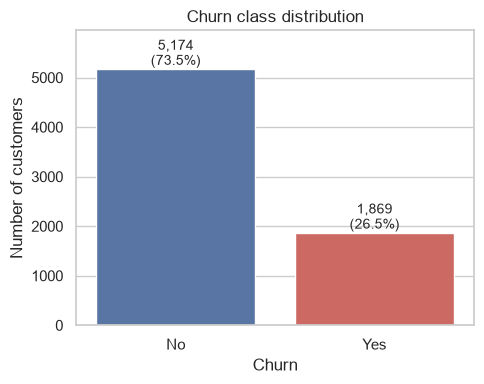

In [12]:
counts = df[TARGET].value_counts()
pct = df[TARGET].value_counts(normalize=True) * 100
display(pd.DataFrame({"count": counts, "percent": pct.round(2)}))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x=TARGET, hue=TARGET, palette=CHURN_PALETTE, legend=False, ax=ax)
for p, label in zip(ax.patches, [f"{counts[k]:,}\n({pct[k]:.1f}%)" for k in ["No", "Yes"]]):
    ax.annotate(label, (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Churn class distribution")
ax.set_ylabel("Number of customers")
ax.set_ylim(0, counts.max() * 1.15)
save_fig("01_churn_distribution")
plt.show()

## Numerical Features

In [13]:
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [14]:
# Summary statistics split by churn
df.groupby(TARGET)[num_cols].agg(["mean", "median"]).round(2)

tenure        MonthlyCharges        TotalCharges         
        mean median           mean median         mean   median
Churn                                                          
No     37.57   38.0          61.27  64.43      2549.91  1679.52
Yes    17.98   10.0          74.44  79.65      1531.80   703.55

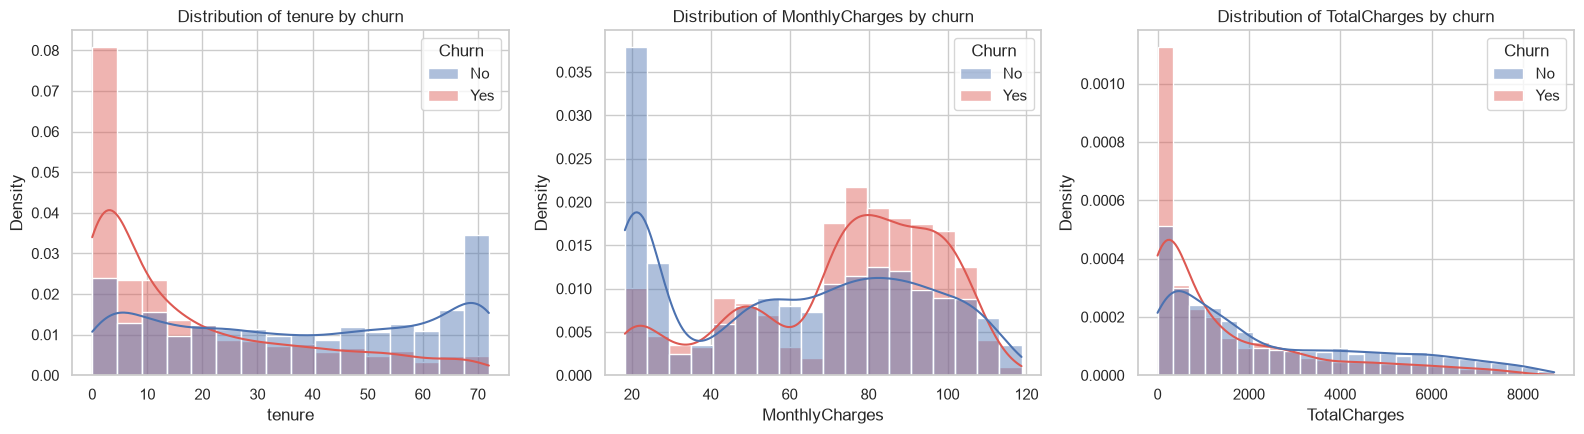

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue=TARGET, palette=CHURN_PALETTE,
                 kde=True, stat="density", common_norm=False, alpha=0.45, ax=ax)
    ax.set_title(f"Distribution of {col} by churn")
save_fig("02_numeric_distributions")
plt.show()

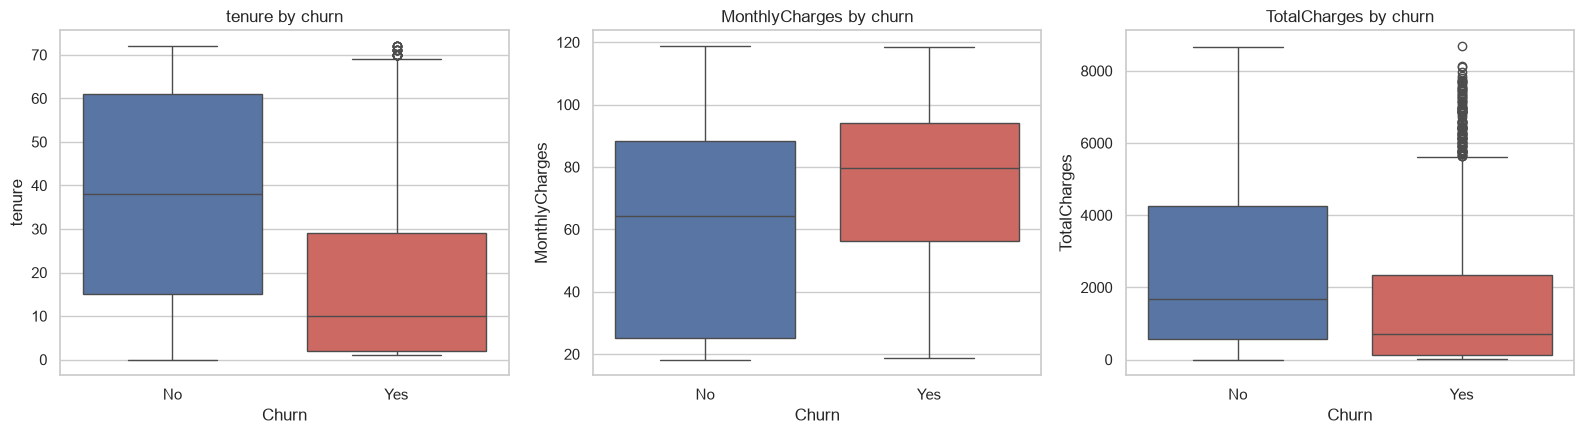

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df, x=TARGET, y=col, hue=TARGET, palette=CHURN_PALETTE, legend=False, ax=ax)
    ax.set_title(f"{col} by churn")
save_fig("03_numeric_boxplots")
plt.show()

In [17]:
# Skewness: large values suggest scaling or transformation may help distance-based models (KNN)
df[num_cols].skew().round(2)

tenure            0.24
MonthlyCharges   -0.22
TotalCharges      0.96
dtype: float64

## Categorical Features

In [18]:
# Detailed tables for the most important categorical features
def churn_rate_table(col):
    """Count and churn rate (%) for each category of a column."""
    return (df.groupby(col)["churn_flag"]
              .agg(customers="count", churn_rate="mean")
              .assign(churn_rate=lambda t: (t["churn_rate"] * 100).round(1))
              .sort_values("churn_rate", ascending=False))

for col in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]:
    display(churn_rate_table(col))

,customers,churn_rate
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


,customers,churn_rate
InternetService,,
Fiber optic,3096,41.9
DSL,2421,19.0
No,1526,7.4


,customers,churn_rate
PaymentMethod,,
Electronic check,2365,45.3
Mailed check,1612,19.1
Bank transfer (automatic),1544,16.7
Credit card (automatic),1522,15.2


,customers,churn_rate
TechSupport,,
No,3473,41.6
Yes,2044,15.2
No internet service,1526,7.4


,customers,churn_rate
OnlineSecurity,,
No,3498,41.8
Yes,2019,14.6
No internet service,1526,7.4


## Feature Interactions

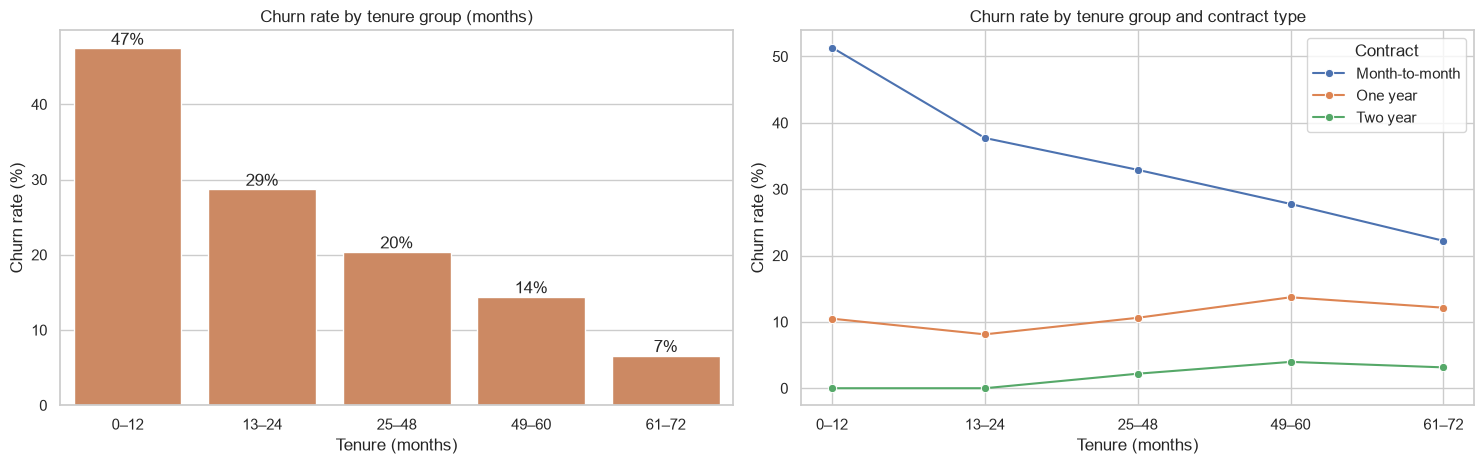

In [19]:
# Tenure bands make the tenure effect easy to read
bins = [0, 12, 24, 48, 60, 72]
labels = ["0–12", "13–24", "25–48", "49–60", "61–72"]
df["tenure_group"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

rate_by_tenure = df.groupby("tenure_group", observed=True)["churn_flag"].mean() * 100
sns.barplot(x=rate_by_tenure.index, y=rate_by_tenure.values, color="#DD8452", ax=axes[0])
axes[0].set_title("Churn rate by tenure group (months)")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Churn rate (%)")
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.0f}%", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")

rate_contract_tenure = (df.groupby(["tenure_group", "Contract"], observed=True)["churn_flag"]
                          .mean().mul(100).reset_index())
sns.lineplot(data=rate_contract_tenure, x="tenure_group", y="churn_flag", hue="Contract",
             marker="o", ax=axes[1])
axes[1].set_title("Churn rate by tenure group and contract type")
axes[1].set_xlabel("Tenure (months)")
axes[1].set_ylabel("Churn rate (%)")
save_fig("04_tenure_interactions")
plt.show()

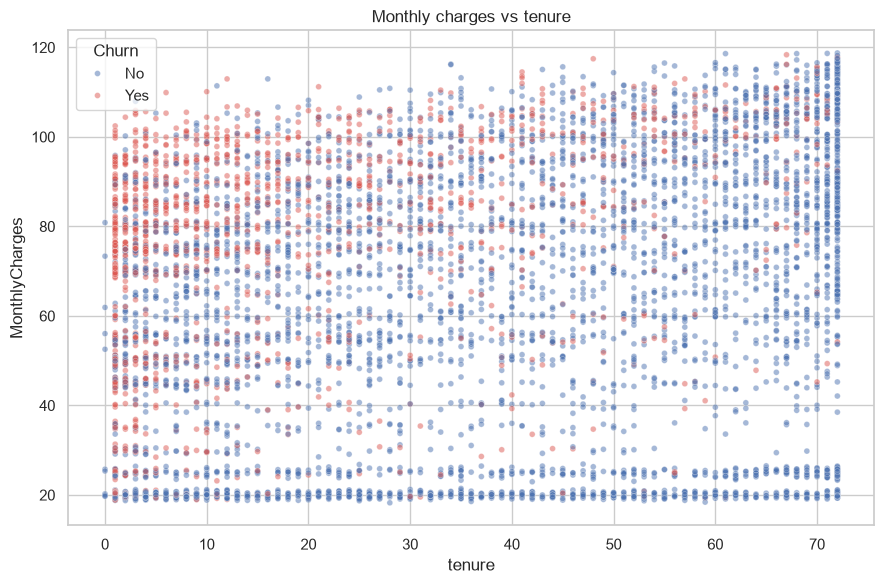

In [20]:
# Monthly charges vs tenure, coloured by churn
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="tenure", y="MonthlyCharges", hue=TARGET,
                palette=CHURN_PALETTE, alpha=0.5, s=18, ax=ax)
ax.set_title("Monthly charges vs tenure")
save_fig("05_tenure_vs_monthly_charges")
plt.show()

In [21]:
# Number of optional add-on services each customer has
addon_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addons"] = (df[addon_cols] == "Yes").sum(axis=1)

addon_rate = df.groupby("num_addons")["churn_flag"].agg(["count", "mean"])
addon_rate["mean"] = (addon_rate["mean"] * 100).round(1)
addon_rate.columns = ["customers", "churn_rate (%)"]
display(addon_rate)

,customers,churn_rate (%)
num_addons,,
0,2219,21.4
1,966,45.8
2,1033,35.8
3,1118,27.4
4,852,22.3
5,571,12.4
6,284,5.3


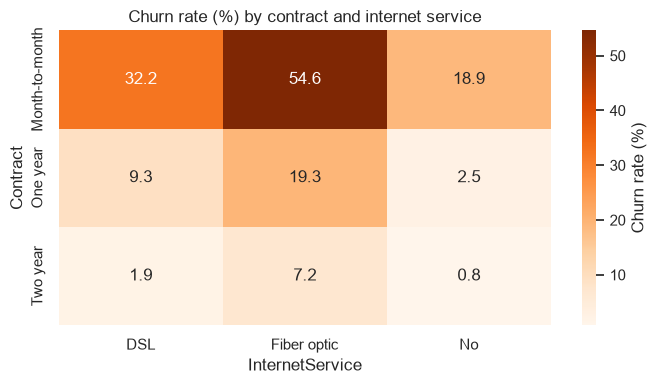

In [22]:
# Contract x InternetService heatmap of churn rate
pivot = df.pivot_table(index="Contract", columns="InternetService",
                       values="churn_flag", aggfunc="mean") * 100
fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Oranges", cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate (%) by contract and internet service")
save_fig("06_contract_internet_heatmap")
plt.show()

## Correlation Analysis

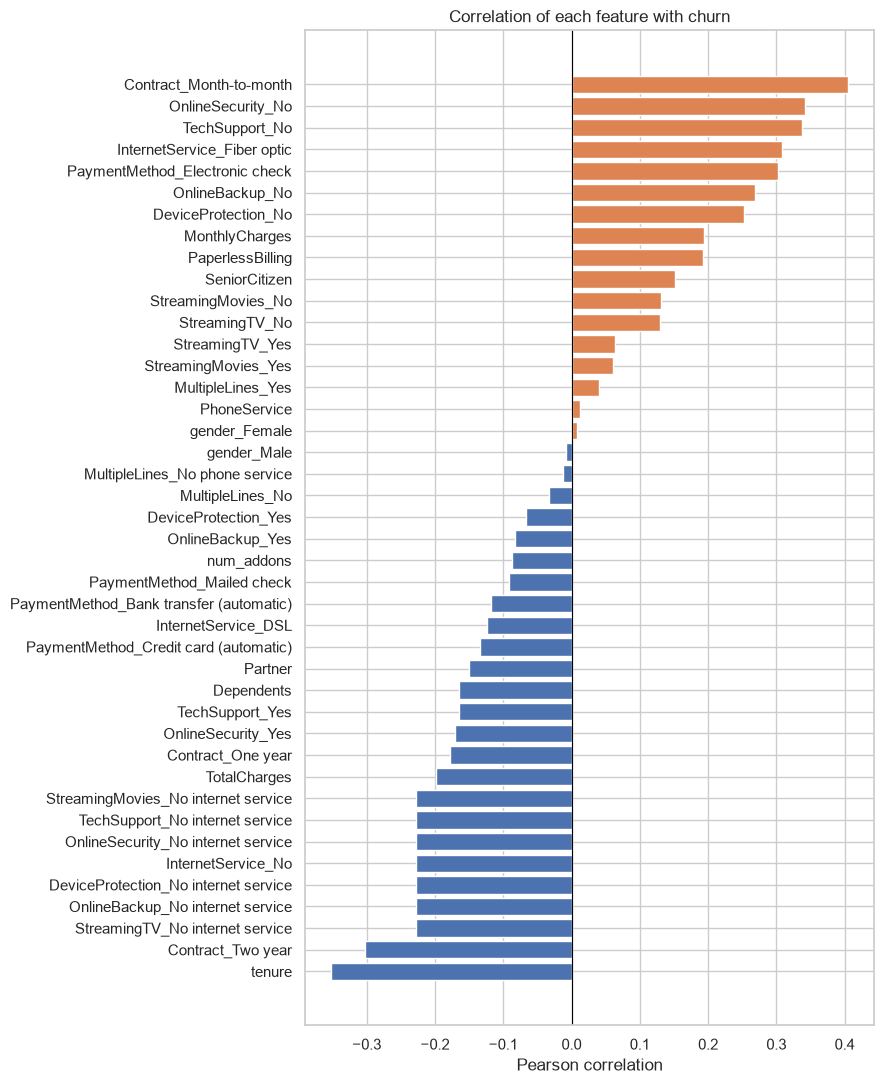

In [23]:
# Encode the binary Yes/No columns as 0/1 and one-hot encode the rest (for analysis only)
corr_df = df.drop(columns=["tenure_group", TARGET]).copy()
binary_cols = [c for c in cat_cols if set(corr_df[c].unique()) <= {"Yes", "No"}]
corr_df[binary_cols] = corr_df[binary_cols].apply(lambda s: (s == "Yes").astype(int))
corr_df = pd.get_dummies(corr_df, drop_first=False, dtype=int)

# Correlation of every feature with churn
churn_corr = corr_df.corr()["churn_flag"].drop("churn_flag").sort_values()

fig, ax = plt.subplots(figsize=(9, 11))
colors = ["#4C72B0" if v < 0 else "#DD8452" for v in churn_corr.values]
ax.barh(churn_corr.index, churn_corr.values, color=colors)
ax.axvline(0, color="black", lw=0.8)
ax.set_title("Correlation of each feature with churn")
ax.set_xlabel("Pearson correlation")
save_fig("07_feature_correlation_with_churn")
plt.show()

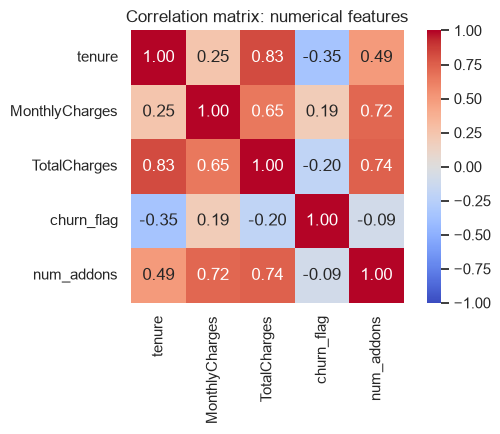

In [24]:
# Correlation between the numerical features (multicollinearity check)
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.heatmap(df[num_cols + ["churn_flag", "num_addons"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlation matrix: numerical features")
save_fig("8_numeric_correlation_heatmap")
plt.show()

## Summary Of Insights

| # | Finding | Evidence | Implication for modelling |
|---|---------|----------|---------------------------|
| 1 | The target is imbalanced | 73.5% No vs 26.5% Yes | Stratified split and CV; evaluate with recall, F1 and ROC-AUC rather than accuracy; compare a baseline with SMOTE / class weights |
| 2 | 11 blank `TotalCharges` values | All have `tenure = 0` and were never billed | Filled with 0 rather than dropped or mean-imputed |
| 3 | Contract type is the strongest predictor | Month-to-month 42.7% vs two-year 2.8% churn; Cramér's V = 0.41 | Keep; one-hot encode |
| 4 | New customers churn most | 47% churn in first 12 months vs 7% after 60 months; median tenure 10 vs 38 months | Keep `tenure`; `tenure_group` is a candidate engineered feature |
| 5 | Higher monthly charges raise churn | Median $79.65 (churned) vs $64.43 (stayed) | Keep; scale for KNN and Logistic Regression |
| 6 | Fibre optic and electronic check customers are high-risk | 41.9% and 45.3% churn; month-to-month + fibre reaches 54.6% | One-hot encode `InternetService` and `PaymentMethod` |
| 7 | Security and support add-ons protect against churn | No `OnlineSecurity` 41.8% vs Yes 14.6%; `TechSupport` 41.6% vs 15.2% | Keep; `num_addons` is a candidate engineered feature |
| 8 | `TotalCharges` is largely redundant | ≈ tenure × MonthlyCharges; r = 0.83 with tenure | Multicollinearity risk for Logistic Regression; consider dropping or regularising |
| 9 | `gender` and `PhoneService` show no significant link to churn | χ² p = 0.49 and p = 0.34 | Candidates for removal; `gender` is also relevant to the fairness analysis in Task 3 |
| 10 | Features use very different scales and are mostly categorical | tenure 0–72, TotalCharges 0–8,685; 16 categorical columns | Scaling and encoding inside a pipeline, fitted on training data only |